# Xtech US Equity Flow Factors (EFF1)

A quick tour of the three EFF1 datasets on Unifier: daily factor values, reference
portfolio weights, and the simulated P&L of those portfolios.

Two factors are live at the moment:

- `FS_01`: structural patterns in equity trading activity
- `FS_02`: the same trading-activity signal, adjusted for recent dollar volume

Each one has a reference long/short portfolio on the Russell 1000 (`FS_01_R1K`, `FS_02_R1K`).

Some background before you start:

- Factors cover the Russell 1000 + Russell 2000 members on each date. Any stock with
  enough input data gets a value, even if it can't go into the reference portfolio.
- `score` ranks that whole universe from -100 to +100, higher means more long.
  It's a rank, not a return forecast.
- The rank transforms and residual controls are calibrated on R1000 stocks only and
  then applied to everything else, so the extra R2000 names don't change R1000 values.
- The reference portfolios re-rank `factor_value` within the R1000 rather than using
  `score`. They run 20 overlapping daily sleeves and hedge out the first 3 PCA factors.

You need a demo token in the `UNIFIER_TOKEN` environment variable to run this.

In [2]:
%pip install -q "unifier==0.1.23" pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\KiwiTech.DESKTOP-8A4SPSP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from unifier import unifier as Unifier

# Unifier.user = 'unifier username'
# Unifier.token = 'unifier api token'
Unifier.user = "demo"
Unifier.token = "qZy7KpE+L5Fg2MmjFqC/1xmweo7pgnnACCcK3JNEAec="
os.environ['UNIFIER_USER'] = Unifier.user
os.environ['UNIFIER_TOKEN'] = Unifier.token

pd.set_option("display.max_columns", 20)

## Settings

Each dataset is dated differently:

- factors: the signal date
- weights: the next open, when you would trade them
- P&L: the open at the end of each return interval

So the 2026-10-06 signal gives the 2026-10-07 weights. The P&L pull goes back to the
start of the published history, 2017-01-06.

In [2]:
# Unifier catalog names
FACTORS = "xtech_us_equity_flow_factors_factors_daily"
WEIGHTS = "xtech_us_equity_flow_factors_weights_daily"
PNL = "xtech_us_equity_flow_factors_pnl_daily"

factor_ids = ["FS_01", "FS_02"]
portfolio_ids = ["FS_01_R1K", "FS_02_R1K"]
factor_filter = "factor_id IN ('FS_01', 'FS_02')"
portfolio_filter = "portfolio_id IN ('FS_01_R1K', 'FS_02_R1K')"

signal_date = "2026-10-06"
trade_date = "2026-10-07"  # next open after signal_date
history_start = "2026-09-01"
pnl_start = "2017-01-06"
ticker = "AAPL"

## What's in each dataset

Every dataset has a description and a column dictionary in the catalog.

In [3]:
for name in [FACTORS, WEIGHTS, PNL]:
    details = Unifier.get_dataset_details(name=name)
    print(details["private_title"])
    print(details["private_description"])
    display(pd.DataFrame(details["data_dictionary"]["data_dictionary"]))

Xtech US Equity Flow Factors - Factors (Daily)
Stock factor values, oriented scores and availability statuses across the broad calculation universe. Current examples FS_01 and FS_02 use reference R1k calibration applied to dated R1k+R2k; additional factors may declare different calibration. Grain: Signal session x factor x universe x security. Separate daily files per public factor or portfolio; default no overwrite; manual repair. Partitioned by factor_id and asof_date.


,data_type,column_name,description
0,varchar,asof_datetime,"Recorded publication timestamp, ISO-8601 UTC; ..."
1,varchar,universe,Dated factor calculation and scoring universe.
2,varchar,secid,Stable security identifier.
3,varchar,ticker,Symbol on the signal date.
4,double,factor_value,Native measurement in the units declared for t...
5,double,score,Oriented average-rank score from -100 to +100;...
6,varchar,status,Public availability status.
7,varchar,factor_id,Public factor identifier; see associated metad...
8,date,asof_date,Signal date for factors; execution date for we...


Xtech US Equity Flow Factors - Weights (Daily)
Signed next-open target weights for each reference strategy, including its market hedge. Current examples: FS_01_R1K and FS_02_R1K. Strategy universes and policies may differ. Grain: Execution session x reference portfolio x security. Separate daily files per public factor or portfolio; default no overwrite; manual repair. Partitioned by portfolio_id and asof_date.


,data_type,column_name,description
0,varchar,asof_datetime,"Recorded publication timestamp, ISO-8601 UTC; ..."
1,varchar,signal_date,"Latest signal date used to form the target, YY..."
2,varchar,factor_id,Public identifier of the associated factor.
3,varchar,universe,Portfolio's dated strategy universe.
4,varchar,secid,Stock or hedge security identifier.
5,varchar,ticker,Symbol known on the signal date.
6,double,target_weight,"Signed fraction of pre-trade NAV; a target, no..."
7,varchar,portfolio_id,Identifier of the reference strategy and its w...
8,date,asof_date,Signal date for factors; execution date for we...


Xtech US Equity Flow Factors - P&L (Daily)
Reference gross/net returns, trading, borrow and financing costs, turnover, exposures and net NAV for each strategy; matched to its portfolio_id in the weights table. Grain: Open-to-open interval x reference portfolio. Separate daily files per public factor or portfolio; default no overwrite; manual repair. Partitioned by portfolio_id and asof_date.


,data_type,column_name,description
0,varchar,asof_datetime,"Recorded publication timestamp, ISO-8601 UTC; ..."
1,varchar,factor_id,Public identifier of the associated factor.
2,varchar,universe,Portfolio's dated strategy universe.
3,varchar,period_start_at,"Return interval start, ISO-8601 UTC."
4,varchar,period_end_at,"Return interval end, ISO-8601 UTC."
5,double,ret_gross,Interval gross return in decimal units.
6,double,ret_net,"Interval return after disclosed trading, borro..."
7,double,cost_trading,Interval trading cost divided by previous net ...
8,double,cost_borrow,Interval borrow cost divided by previous net NAV.
9,double,cost_financing,Financing and cash-interest cost divided by pr...


## Factors on one day

Pull both factors for the signal date. Don't set a `limit` here, you want every stock.

`factor_value` is in each factor's own units, `score` is the -100 to +100 rank.
Check `status` and the nulls before building anything on top of it.

In [4]:
factors = Unifier.get_dataframe(name=FACTORS, asof_date=signal_date, column_filters=factor_filter)
assert len(factors) > 0, "nothing came back, check the token and the date"
factors["asof_date"] = pd.to_datetime(factors["asof_date"])
factors.head(10)

,asof_datetime,universe,secid,ticker,factor_value,score,status,factor_id,asof_date
0,2026-10-09T15:50:04.930297Z,R1k_R2k,10005944,PR,0.230389,58.070998,ok,FS_02,2026-10-06
1,2026-10-09T15:50:04.930297Z,R1k_R2k,100112,NTGR,-0.190989,-38.580040,ok,FS_02,2026-10-06
2,2026-10-09T15:50:04.930297Z,R1k_R2k,10011812,MANE,-0.038005,11.051574,ok,FS_02,2026-10-06
3,2026-10-09T15:50:04.930297Z,R1k_R2k,10011935,FPS,0.089372,29.604823,ok,FS_02,2026-10-06
4,2026-10-09T15:50:04.930297Z,R1k_R2k,10012394,EIKN,-0.107118,-3.884796,ok,FS_02,2026-10-06
5,2026-10-09T15:50:04.930297Z,R1k_R2k,10012407,BOBS,-0.121329,-7.367716,ok,FS_02,2026-10-06
6,2026-10-09T15:50:04.930297Z,R1k_R2k,10014502,IRTC,-0.249829,-89.283322,ok,FS_02,2026-10-06
7,2026-10-09T15:50:04.930297Z,R1k_R2k,10017030,LFTO,-0.120907,-7.233758,ok,FS_02,2026-10-06
8,2026-10-09T15:50:04.930297Z,R1k_R2k,10025602,FDXF,-0.199671,-79.102478,ok,FS_02,2026-10-06
9,2026-10-09T15:50:04.930297Z,R1k_R2k,10032023,SGP,-0.194636,-51.741460,ok,FS_02,2026-10-06


In [5]:
factors.groupby(["factor_id", "universe"]).agg(
    stocks=("secid", "nunique"),
    with_value=("factor_value", "count"),
    with_score=("score", "count"),
)

,,stocks,with_value,with_score
factor_id,universe,,,
FS_01,R1k_R2k,2989,2989,2989
FS_02,R1k_R2k,2989,2987,2987


In [6]:
factors.groupby(["factor_id", "status"], dropna=False).size().unstack(fill_value=0)

status,excluded,ok
factor_id,,
FS_01,0,2989
FS_02,2,2987


Top and bottom 5 by score for each factor:

In [7]:
cols = ["factor_id", "secid", "ticker", "factor_value", "score", "status"]
for factor_id, df in factors.dropna(subset=["score"]).groupby("factor_id"):
    display(pd.concat([df.nlargest(5, "score"), df.nsmallest(5, "score")])[cols])

,factor_id,secid,ticker,factor_value,score,status
4208,FS_01,41054,PTC,0.541043,100.000000,ok
4151,FS_01,40678,NVDA,0.521750,99.933066,ok
5637,FS_01,763665,PM,0.476383,99.866131,ok
3047,FS_01,10695910,SPCX,0.459522,99.799197,ok
3899,FS_01,38416,INTC,0.439363,99.732262,ok
4613,FS_01,44053,VHI,-0.883526,-100.000000,ok
5848,FS_01,89774,PED,-0.883185,-99.933066,ok
4195,FS_01,40943,PAMT,-0.876391,-99.866131,ok
5743,FS_01,8217883,FBYD,-0.860236,-99.799197,ok
3744,FS_01,36851,FGBI,-0.852551,-99.732262,ok


,factor_id,secid,ticker,factor_value,score,status
990,FS_02,39165,LXP,0.703078,100.000000,ok
1024,FS_02,39453,HZO,0.696179,99.933021,ok
2687,FS_02,78344,SYNA,0.665133,99.866042,ok
2379,FS_02,6864767,BWMN,0.650249,99.799062,ok
303,FS_02,2701301,APAM,0.626418,99.732083,ok
960,FS_02,38946,KLAC,-0.714349,-100.000000,ok
1286,FS_02,41543,BKNG,-0.699440,-99.933021,ok
1883,FS_02,5102194,CVNA,-0.653459,-99.866042,ok
411,FS_02,33214,AXP,-0.561498,-99.799062,ok
2193,FS_02,6354194,AON,-0.554797,-99.732083,ok


## FS_01 vs FS_02

Compare `score` rather than `factor_value`, since the two factors aren't in the same
units. Join on `secid`, which stays fixed over time (tickers don't).

factor_id,FS_01,FS_02
factor_id,,
FS_01,1.000000,0.796452
FS_02,0.796452,1.000000


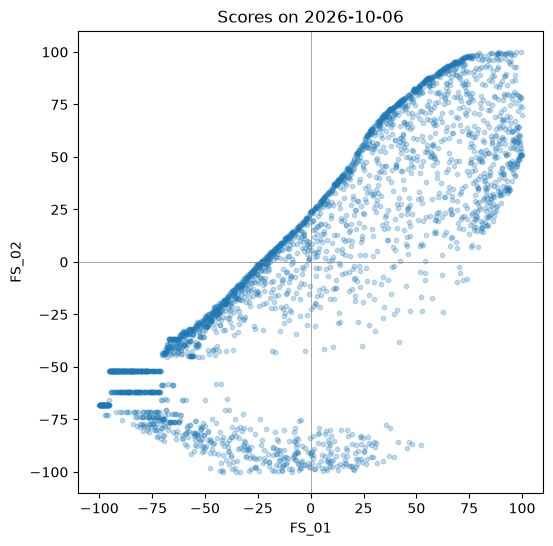

In [9]:
scores = factors.pivot(index="secid", columns="factor_id", values="score").dropna()
display(scores.corr())

ax = scores.plot.scatter(x="FS_01", y="FS_02", s=10, alpha=0.25, figsize=(6, 6), title=f"Scores on {signal_date}")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
plt.show()

## One stock over time

Look up the ticker's `secid` on the signal date and pass it as `key`.

For a date range use `asof_back_to` and `up_to`. Don't add `asof_date` as well, that
limits the query to a single day. `back_to`/`up_to` on their own also only return the
latest snapshot for these datasets.

In [10]:
ids = factors.loc[factors["ticker"] == ticker, "secid"].unique()
assert len(ids) == 1, f"{ticker} matches {len(ids)} secids on {signal_date}"
secid = str(ids[0])

history = Unifier.get_dataframe(
    name=FACTORS,
    key=secid,
    asof_back_to=history_start,
    up_to=signal_date,
    column_filters=factor_filter,
)
history["asof_date"] = pd.to_datetime(history["asof_date"])
history.sort_values(["asof_date", "factor_id"]).tail(10)

,asof_datetime,universe,secid,ticker,factor_value,score,status,factor_id,asof_date
41,2026-10-09T15:49:34.768504Z,R1k_R2k,33449,AAPL,0.451698,99.732620,ok,FS_01,2026-09-30
23,2026-10-09T15:49:34.768504Z,R1k_R2k,33449,AAPL,0.220747,52.040134,ok,FS_02,2026-09-30
29,2026-10-09T15:49:42.284899Z,R1k_R2k,33449,AAPL,0.359746,99.331551,ok,FS_01,2026-10-01
18,2026-10-09T15:49:42.284899Z,R1k_R2k,33449,AAPL,0.184563,45.685619,ok,FS_02,2026-10-01
28,2026-10-09T15:49:50.109515Z,R1k_R2k,33449,AAPL,0.375677,99.465241,ok,FS_01,2026-10-02
39,2026-10-09T15:49:50.109515Z,R1k_R2k,33449,AAPL,0.195651,50.969900,ok,FS_02,2026-10-02
16,2026-10-09T15:49:57.486665Z,R1k_R2k,33449,AAPL,0.367343,99.264460,ok,FS_01,2026-10-05
42,2026-10-09T15:49:57.486665Z,R1k_R2k,33449,AAPL,0.223183,60.722650,ok,FS_02,2026-10-05
12,2026-10-09T15:50:04.930297Z,R1k_R2k,33449,AAPL,0.331579,98.995984,ok,FS_01,2026-10-06
13,2026-10-09T15:50:04.930297Z,R1k_R2k,33449,AAPL,0.186099,49.095780,ok,FS_02,2026-10-06


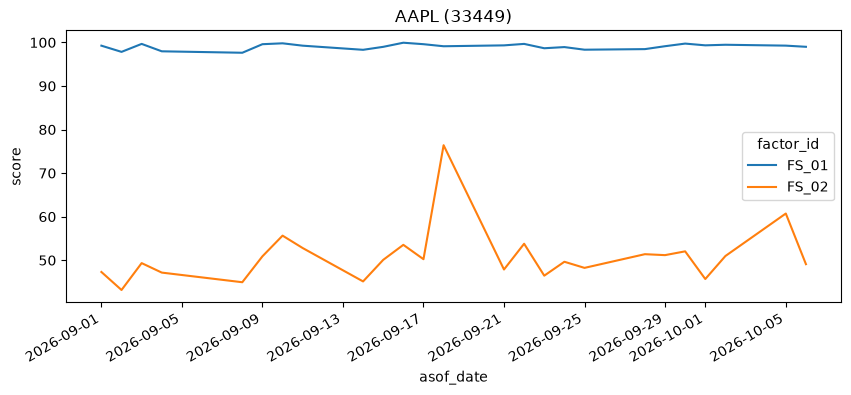

In [11]:
history.pivot(index="asof_date", columns="factor_id", values="score").plot(
    figsize=(10, 4), title=f"{ticker} ({secid})", ylabel="score"
)
plt.show()

## Reference portfolio weights

`target_weight` is a signed fraction of pre-trade NAV. The alpha and hedge legs are
already netted per stock, and a weight of 0 means close the position. These are
targets, so actual holdings end up a little different after trading and costs.

In [12]:
weights = Unifier.get_dataframe(name=WEIGHTS, asof_date=trade_date, column_filters=portfolio_filter)
w = weights["target_weight"]

weights.assign(long=w.clip(lower=0), short=w.clip(upper=0), gross=w.abs()).groupby("portfolio_id").agg(
    names=("secid", "nunique"),
    long=("long", "sum"),
    short=("short", "sum"),
    gross=("gross", "sum"),
    net=("target_weight", "sum"),
).round(4)

,names,long,short,gross,net
portfolio_id,,,,,
FS_01_R1K,1019,1.0,-1.0,2.0,-0.0
FS_02_R1K,1019,1.0,-1.0,2.0,-0.0


In [13]:
# 10 biggest positions in each portfolio
cols = ["signal_date", "portfolio_id", "factor_id", "secid", "ticker", "target_weight"]
top = weights.assign(size=w.abs()).sort_values(["portfolio_id", "size"], ascending=[True, False])
top.groupby("portfolio_id").head(10)[cols]

,signal_date,portfolio_id,factor_id,secid,ticker,target_weight
1139,20261006,FS_01_R1K,FS_01,32924,AES,-0.007977
1325,20261006,FS_01_R1K,FS_01,36950,USB,0.006775
1245,20261006,FS_01_R1K,FS_01,35052,KO,0.006669
1919,20261006,FS_01_R1K,FS_01,72642,MDLZ,0.006480
1936,20261006,FS_01_R1K,FS_01,75787,DOX,-0.006416
1999,20261006,FS_01_R1K,FS_01,8898917,ECG,-0.006303
1761,20261006,FS_01_R1K,FS_01,5122670,IR,0.006199
1794,20261006,FS_01_R1K,FS_01,5744550,MRNA,0.006166
1943,20261006,FS_01_R1K,FS_01,7742226,DRS,-0.006150
1274,20261006,FS_01_R1K,FS_01,35608,DHI,0.006138


## P&L

`portfolio_id` links the weights to the P&L. Returns and costs are decimals (0.01 = 1%),
and `nav_net` is the simulated net NAV.

Simulation assumptions:

- trade at the next open, P&L measured open to open
- 5 bps cost on one-way traded notional
- borrow, market impact and financing are set to zero, and cash interest isn't modeled

`asof_datetime` is when a row was actually published, so backfilled history carries
the backfill time. Trading at the next open is an assumption for those dates, not
something that happened.

Up to 2026-09-28 the P&L matches our research backtest, and after that it's the
production job rolling forward day by day. All of it is simulated, and the backtest
period was already seen during research, so treat it as in-sample.

When a stock is acquired or delisted it drops out of the factors and weights, but the
P&L still books the cash or shares it was settled for. The 2026-10-05 and 2026-10-06
rows include a few of these.

In [14]:
pnl = Unifier.get_dataframe(name=PNL, keys=portfolio_ids, asof_back_to=pnl_start, up_to=signal_date)
assert len(pnl) > 0, "no P&L came back"
pnl["asof_date"] = pd.to_datetime(pnl["asof_date"])
pnl.sort_values(["asof_date", "portfolio_id"]).tail(10)

,asof_datetime,factor_id,universe,period_start_at,period_end_at,ret_gross,ret_net,cost_trading,cost_borrow,cost_financing,turnover,gross_exposure,net_exposure,nav_net,portfolio_id,asof_date
3482,2026-10-09T15:49:38.922601Z,FS_01,r1k,2026-09-29T13:30:00+00:00,2026-09-30T13:30:00+00:00,0.000084,0.000038,0.000046,0,0,0.092113,2.000092,-1.652556e-16,1.847510,FS_01_R1K,2026-09-30
465,2026-10-09T15:49:38.922601Z,FS_02,r1k,2026-09-29T13:30:00+00:00,2026-09-30T13:30:00+00:00,0.000789,0.000728,0.000061,0,0,0.121036,2.000121,3.438762e-17,1.614277,FS_02_R1K,2026-09-30
4807,2026-10-09T15:49:46.452209Z,FS_01,r1k,2026-09-30T13:30:00+00:00,2026-10-01T13:30:00+00:00,-0.002415,-0.002458,0.000043,0,0,0.086696,2.000087,-1.656629e-16,1.842968,FS_01_R1K,2026-10-01
1756,2026-10-09T15:49:46.452209Z,FS_02,r1k,2026-09-30T13:30:00+00:00,2026-10-01T13:30:00+00:00,-0.003993,-0.004049,0.000057,0,0,0.113628,2.000114,0.000000e+00,1.607741,FS_02_R1K,2026-10-01
3980,2026-10-09T15:49:54.182011Z,FS_01,r1k,2026-10-01T13:30:00+00:00,2026-10-02T13:30:00+00:00,-0.004824,-0.004870,0.000046,0,0,0.092133,2.000092,1.513397e-17,1.833992,FS_01_R1K,2026-10-02
4018,2026-10-09T15:49:54.182011Z,FS_02,r1k,2026-10-01T13:30:00+00:00,2026-10-02T13:30:00+00:00,-0.001767,-0.001826,0.000059,0,0,0.118775,2.000119,-1.729530e-17,1.604804,FS_02_R1K,2026-10-02
987,2026-10-09T15:50:01.661357Z,FS_01,r1k,2026-10-02T13:30:00+00:00,2026-10-05T13:30:00+00:00,-0.001015,-0.001058,0.000043,0,0,0.086746,2.000087,3.787499e-17,1.832052,FS_01_R1K,2026-10-05
2855,2026-10-09T15:50:01.661357Z,FS_02,r1k,2026-10-02T13:30:00+00:00,2026-10-05T13:30:00+00:00,0.000533,0.000478,0.000056,0,0,0.111023,2.000111,-3.457409e-17,1.605571,FS_02_R1K,2026-10-05
1188,2026-10-09T15:50:09.401952Z,FS_01,r1k,2026-10-05T13:30:00+00:00,2026-10-06T13:30:00+00:00,0.000410,0.000366,0.000044,0,0,0.088650,2.000089,-1.628030e-16,1.832721,FS_01_R1K,2026-10-06
4019,2026-10-09T15:50:09.401952Z,FS_02,r1k,2026-10-05T13:30:00+00:00,2026-10-06T13:30:00+00:00,-0.000467,-0.000525,0.000058,0,0,0.116542,2.000117,3.459226e-17,1.604728,FS_02_R1K,2026-10-06


## Performance

Compound `ret_net` starting from NAV = 1, drawdown from the running peak, and Sharpe
with 252 days a year and no risk-free rate.

In [15]:
rets = pnl.pivot(index="asof_date", columns="portfolio_id", values="ret_net").dropna()  # common dates only
nav = (1 + rets).cumprod()
drawdown = nav / nav.cummax().clip(lower=1) - 1

print(f"{rets.index[0]:%Y-%m-%d} to {rets.index[-1]:%Y-%m-%d}")
pd.DataFrame({
    "days": rets.count(),
    "total_return": nav.iloc[-1] - 1,
    "ann_vol": rets.std() * 252**0.5,
    "sharpe": rets.mean() / rets.std() * 252**0.5,
    "max_drawdown": drawdown.min(),
})

2017-01-06 to 2026-10-06


,days,total_return,ann_vol,sharpe,max_drawdown
portfolio_id,,,,,
FS_01_R1K,2450,0.832721,0.049087,1.294060,-0.069157
FS_02_R1K,2450,0.604728,0.036249,1.360225,-0.030592


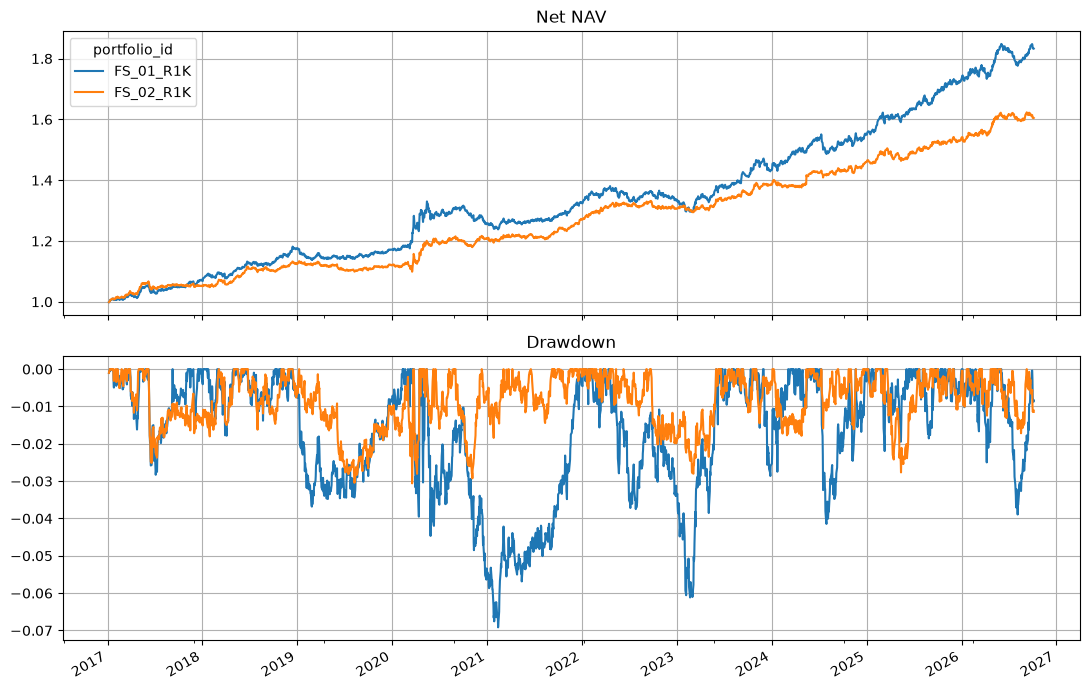

In [16]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
nav.plot(ax=ax1, title="Net NAV", grid=True)
drawdown.plot(ax=ax2, title="Drawdown", grid=True, legend=False)
ax2.set_xlabel("")
plt.tight_layout()
plt.show()